In [1]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path('../data')
train_csv_path = DATA_DIR / 'Train.csv'

try:
    train_df = pd.read_csv(train_csv_path)
    print("CSV file loaded successfully!")
except FileNotFoundError:
    print(f"Error: The file was not found at {train_csv_path}")

if 'train_df' in locals():
    print(f"\nDataFrame Shape: {train_df.shape}")
    print("\n--- First 5 Rows ---")
    print(train_df.head())
    print("\n--- DataFrame Info ---")
    train_df.info()

CSV file loaded successfully!

DataFrame Shape: (39209, 8)

--- First 5 Rows ---
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                             Path  
0  Train/20/00020_00000_00000.png  
1  Train/20/00020_00000_00001.png  
2  Train/20/00020_00000_00002.png  
3  Train/20/00020_00000_00003.png  
4  Train/20/00020_00000_00004.png  

--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 39209 entries, 0 to 39208
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Width    39209 non-null  int64
 1   Height   39209 non-null  int64
 2   Roi.X1   39209 non-null  int64
 3   Roi.Y1   39209 non-null  int64

Shape: 39.209 Einträge im Train, keine fehlenden Werte in keiner Spalte. Jede hat 8 zusammengehörige Informationseinheiten
| Spalte | Bedeutung |
|---|---|
| `Width`, `Height` | Bildgröße in Pixeln |
| `Roi.X1/Y1/X2/Y2` | Begrenzungsrahmen des Verkehrszeichens (oben-links & unten-rechts)|
| `ClassId` | Zielklasse als Integer (z. B. 1 = „Tempo 30") – das, was das Modell vorhersagen soll |

```
Koordinaten im Bild
Der Ursprung (0, 0) liegt in der oberen linken Ecke des Bildes:
X wächst nach rechts.
Y wächst nach unten. Achtung: Das ist umgekehrt zum Koordinatensystem aus der Mathematik.
(0,0) ──────────── X →          (Width = 50)
  │
  │    (5,6) ●───────────┐
  │          │           │
  │          │  SCHILD   │
  │          │           │
  │          └───────────● (45,54)
  ↓
  Y                     (Height = 60)

```

In [2]:
test_csv_path = DATA_DIR / 'Test.csv'

try:
    test_df = pd.read_csv(test_csv_path)
    print("CSV file loaded successfully!")
except FileNotFoundError:
    print(f"Error: The file was not found at {test_csv_path}")

CSV file loaded successfully!


## Visualize Class Distribution with a Bar Chart
Die Spalte ClassId enthält das Ziel-Label jedes Bildes. Bevor wir ein Modell trainieren, stellt sich eine wichtige Frage: Ist der Datensatz ausgewogen? Haben alle 43 Klassen ähnlich viele Trainingsbeispiele, oder gibt es starke Ungleichgewichte? Um das zu beantworten, visualisieren wir die Klassenverteilung als Balkendiagramm

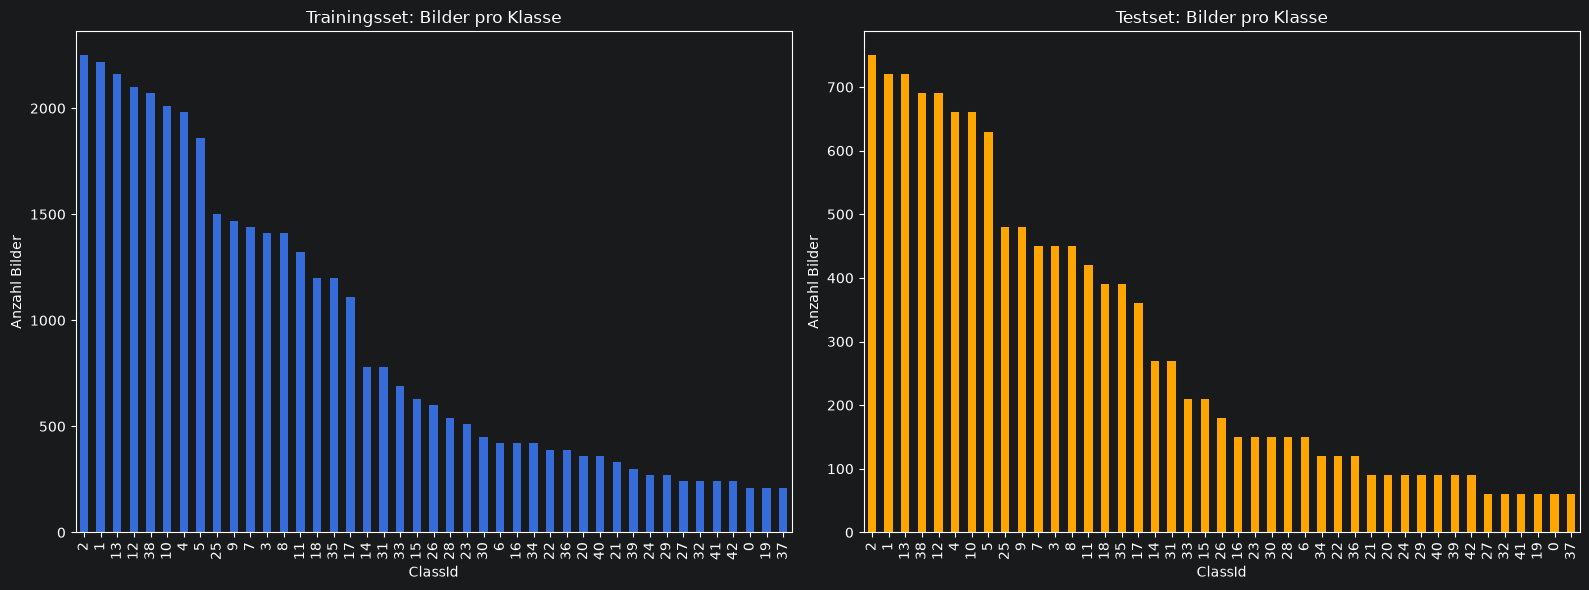

In [3]:
import matplotlib.pyplot as plt

# Check if the DataFrame exists before we use it
if 'train_df' in locals() and 'test_df' in locals():
    # --- 1. Count the occurrences of each ClassId ---
    train_counts = train_df['ClassId'].value_counts()
    test_counts = test_df['ClassId'].value_counts()
    # --- 2. Create the Bar Chart ---
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    # --- 3. Add Titles and Labels for Clarity ---
    train_counts.plot(kind="bar", ax=axes[0])
    axes[0].set_title("Trainingsset: Bilder pro Klasse")
    axes[0].set_xlabel("ClassId")
    axes[0].set_ylabel("Anzahl Bilder")

    test_counts.plot(kind="bar", ax=axes[1], color="orange")
    axes[1].set_title("Testset: Bilder pro Klasse")
    axes[1].set_xlabel("ClassId")
    axes[1].set_ylabel("Anzahl Bilder")
    plt.tight_layout()
    plt.show()
else:
    print("❌ DataFrame 'train_df' not found. Please run the previous cell to load the data first.")


**Schlussfolgerungen aus der Klassenverteilung:**

* **Starke Klassenimbalance im Trainingsset:** Die häufigste Klasse (2, „Tempo 50")
  enthält ca. 2.250 Bilder, die seltensten Klassen (0, 19, 37) nur ca. 210 – ein
  Verhältnis von etwa 10:1. Fast die Hälfte der 43 Klassen hat weniger als 500 Bilder.
* **Test- und Trainingsset sind nahezu gleich verteilt:** Beide Verteilungen haben
  dieselbe Form und fast dieselbe Reihenfolge der Klassen. Das Testset enthält pro
  Klasse etwa ein Drittel der Trainingsbilder und ist damit repräsentativ.
* **Auch das Testset ist unausgewogen** (ca. 750 vs. 60 Bilder pro Klasse). Die
  Gesamt-Accuracy wird daher von den großen Klassen dominiert.
* **Konsequenzen:** Im Training sind Gegenmaßnahmen nötig (gezielte Augmentation,
  Oversampling oder gewichteter Loss). Zur Evaluation sollten zusätzlich klassenweise
  Metriken (Macro-F1, Confusion Matrix) verwendet werden.

## Trainingsdaten visuell überprüfen, indem Beispielbilder angezeigt werden
Die Balkendiagramme gaben uns einen statistischen Überblick über die Anzahl der Bilder pro Klasse und machten die Unausgewogenheit des Datensatzes deutlich sichtbar. Nun verlagern wir unseren Fokus von der Frage „Wie viele?" hin zu „Was genau?" - es ist Zeit, die Rohdaten, aus denen unser Modell lernen soll, direkt unter die Lupe zu nehmen.                                                          Bei einem Computer-Vision-Projekt bedeutet Datenvisualisierung nicht nur Diagramme und Graphen - es bedeutet vor allem, die Bilder selbst zu betrachten. Durch die visuelle Inspektion einer Stichprobe lassen sich folgende Fragen beantworten:
- Bildqualität: Sind die Bilder scharf und klar, oder leiden sie unter Unschärfe, Pixelierung oder Kompressionsartefakten?
- Umgebungsbedingungen: Wie variieren Lichtverhältnisse (Tageslicht, Schatten, Dämmerung), Wetterbedingungen oder mögliche Verdeckungen (z. B.
  durch Äste)?
- Varianz innerhalb einer Klasse: Ein Stoppschild kann aus verschiedenen Winkeln, Entfernungen und Perspektiven aufgenommen sein – diese
  Vielfalt verdeutlicht, wie anspruchsvoll die Aufgabe für das Modell ist.
- Ähnlichkeit zwischen Klassen: Lassen sich „Tempo 30" und „Tempo 50" auf den ersten Blick unterscheiden? Wie steht es um ähnliche
  Abbiegeschilder?

Um dies systematisch zu untersuchen, entwickeln wir eine Python-Funktion, die ein Raster zufällig ausgewählter Bilder aus verschiedenen Klassen erstellt – für einen schnellen visuellen Gesamteindruck des Datensatzes.\
Verwendete Bibliotheken
- OpenCV (cv2): Mit cv2.imread() lesen wir die Bilddateien von der Festplatte.
- Matplotlib (plt): Mit plt.subplots() erstellen wir ein Raster aus einzelnen Achsen, wobei jede Achse als Anzeigefeld für ein Beispielbild dient.

Displaying a random sample of training images...


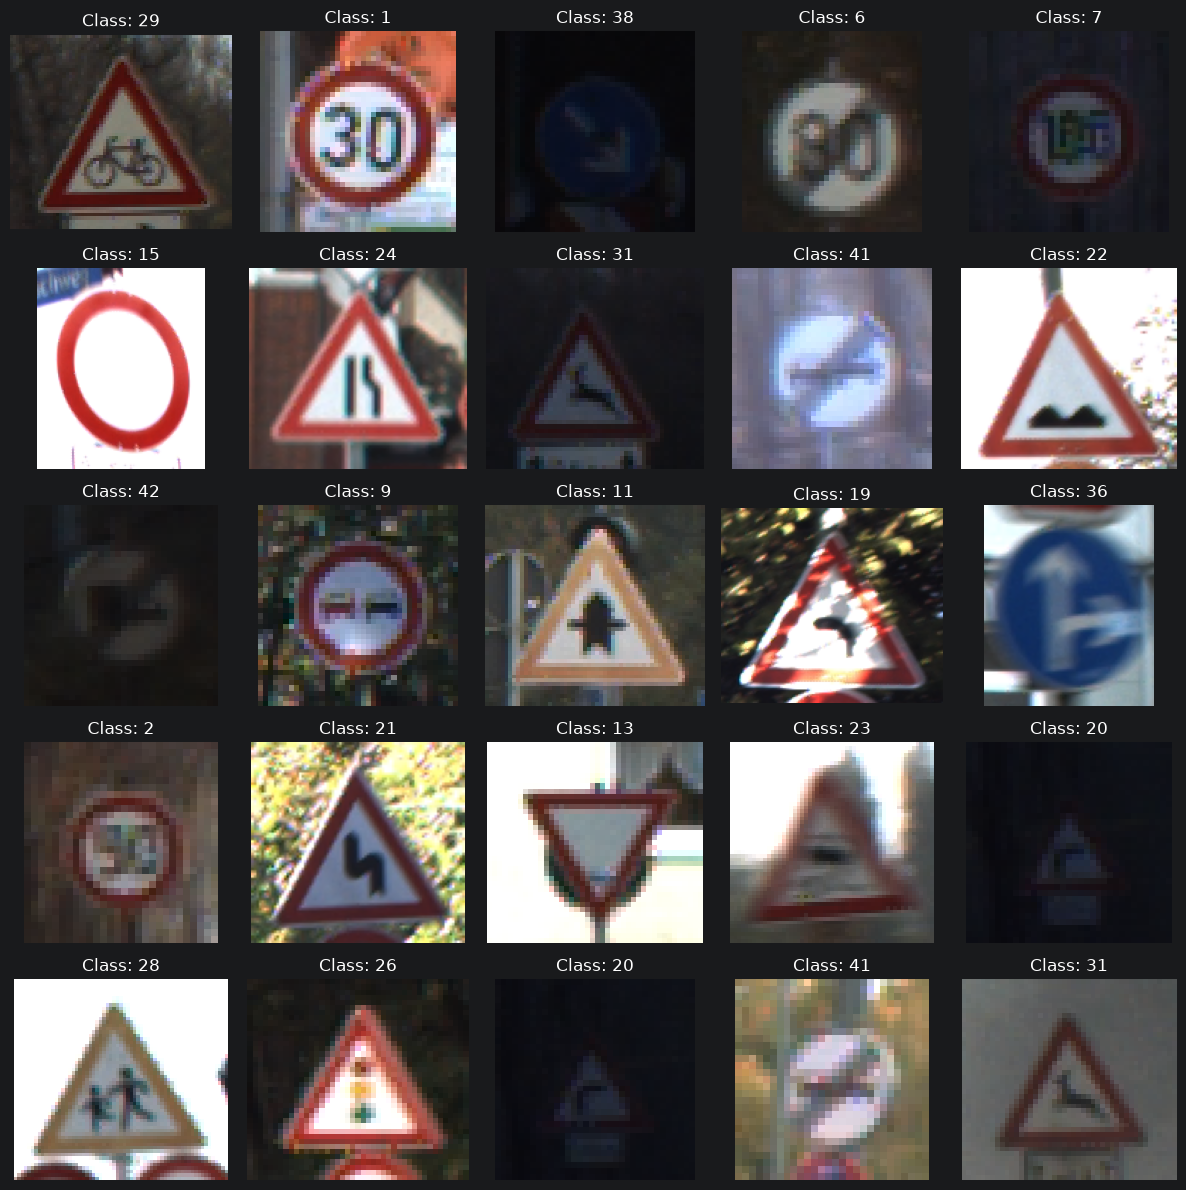

In [4]:
import matplotlib.pyplot as plt
import cv2 # OpenCV for image reading
import random
from pathlib import Path

train_data_path = DATA_DIR / 'Train'

def display_sample_images(data_path, num_rows=5, num_cols=5):
    """
    Displays a grid of randomly selected sample images from different classes.

    Args:
        data_path (Path): Path to the training data directory.
        num_rows (int): Number of rows in the display grid.
        num_cols (int): Number of columns in the display grid.
    """
    # Get a list of all class directories (e.g., '0', '1', '2', ...)
    class_dirs = [d for d in data_path.iterdir() if d.is_dir()]

    if not class_dirs:
        print(f"❌ No class directories found in {data_path}.")
        return

    # Create a figure and a set of subplots
    # plt.subplots returns the figure and an array of axes objects
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(12, 12))

    # Flatten the axes array to make it easy to iterate over
    axes = axes.flatten()

    for i in range(num_rows * num_cols):
        ax = axes[i]

        # --- Randomly select a class and an image ---
        random_class_dir = random.choice(class_dirs)

        # Get a list of all image files in that class directory
        image_files = list(random_class_dir.glob('*.png'))

        if not image_files:
            ax.axis('off') # Turn off axis if no images found
            continue

        # Choose a random image file
        random_image_path = random.choice(image_files)

        # --- Read and display the image ---
        image = cv2.imread(str(random_image_path))

        # ** VERY IMPORTANT STEP **
        # OpenCV reads images in BGR (Blue, Green, Red) channel order by default.
        # Matplotlib, however, expects images in RGB (Red, Green, Blue) order.
        # We must convert the color space to display the colors correctly.
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Display the image on the current axis
        ax.imshow(image_rgb)

        # Set the title of the subplot to the Class ID (which is the directory name)
        ax.set_title(f"Class: {random_class_dir.name}")

        # Turn off the axis ticks and labels for a cleaner look
        ax.axis('off')

    # Adjust layout to prevent titles from overlapping and display the plot
    plt.tight_layout()
    plt.show()

# --- Call the function to display the images ---
print("Displaying a random sample of training images...")
display_sample_images(train_data_path)

## Zuordnung von Klassen-IDs zu Bezeichnungsnamen

In [5]:
# Create the mapping from ClassId to SignName
class_id_to_name = {
    0: 'Speed limit (20km/h)',
    1: 'Speed limit (30km/h)',
    2: 'Speed limit (50km/h)',
    3: 'Speed limit (60km/h)',
    4: 'Speed limit (70km/h)',
    5: 'Speed limit (80km/h)',
    6: 'End of speed limit (80km/h)',
    7: 'Speed limit (100km/h)',
    8: 'Speed limit (120km/h)',
    9: 'No passing',
    10: 'No passing for vehicles over 3.5 metric tons',
    11: 'Right-of-way at the next intersection',
    12: 'Priority road',
    13: 'Yield',
    14: 'Stop',
    15: 'No vehicles',
    16: 'Vehicles over 3.5 metric tons prohibited',
    17: 'No entry',
    18: 'General caution',
    19: 'Dangerous curve to the left',
    20: 'Dangerous curve to the right',
    21: 'Double curve',
    22: 'Bumpy road',
    23: 'Slippery road',
    24: 'Road narrows on the right',
    25: 'Road work',
    26: 'Traffic signals',
    27: 'Pedestrians',
    28: 'Children crossing',
    29: 'Bicycles crossing',
    30: 'Beware of ice/snow',
    31: 'Wild animals crossing',
    32: 'End of all speed and passing limits',
    33: 'Turn right ahead',
    34: 'Turn left ahead',
    35: 'Ahead only',
    36: 'Go straight or right',
    37: 'Go straight or left',
    38: 'Keep right',
    39: 'Keep left',
    40: 'Roundabout mandatory',
    41: 'End of no passing',
    42: 'End of no passing by vehicles over 3.5 metric tons'
}
print("✅ Class ID to Sign Name mapping created successfully!")

✅ Class ID to Sign Name mapping created successfully!


Displaying a random sample of training images with their names...


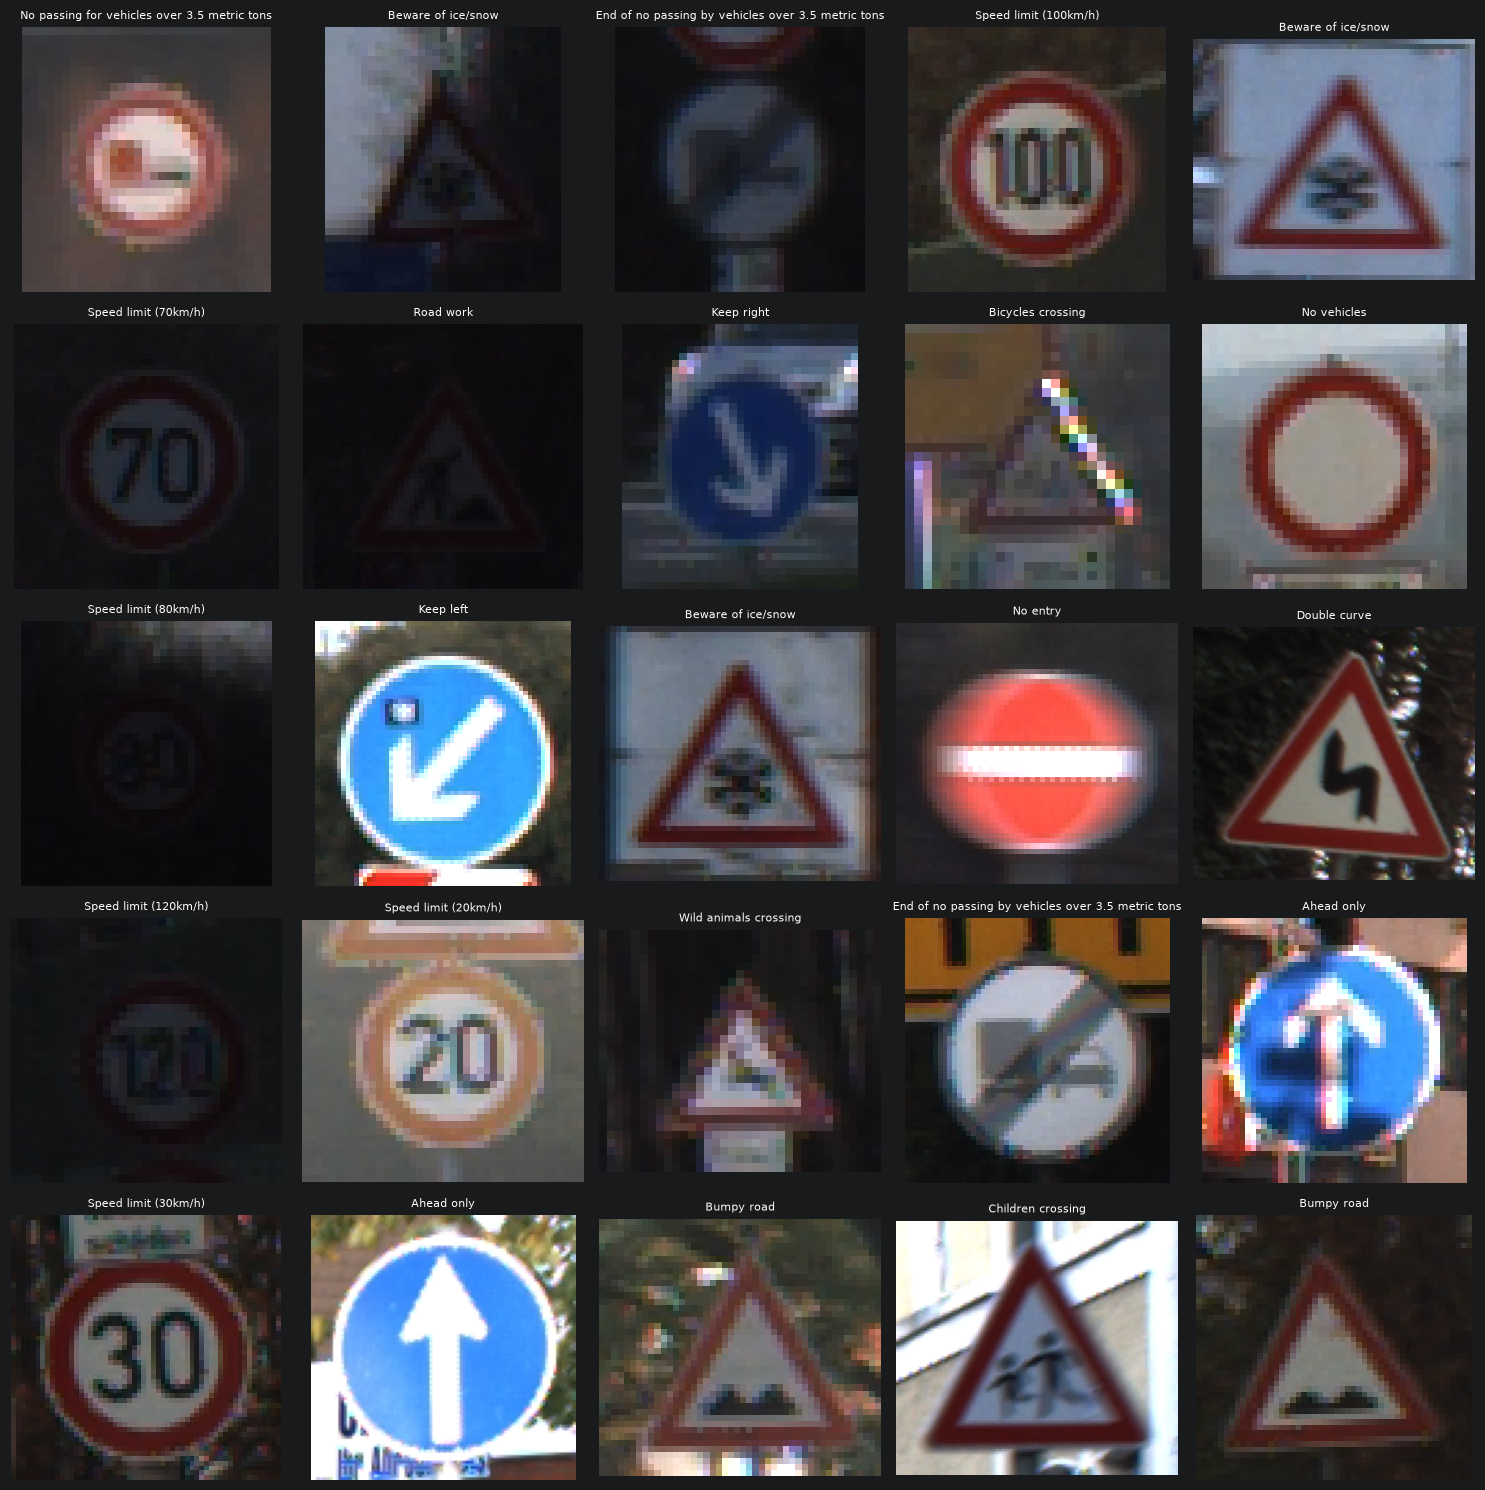

In [6]:
train_data_path = DATA_DIR / 'Train'

def display_sample_images_with_names(data_path, class_mapping, num_rows=5, num_cols=5):
    """
    Displays a grid of randomly selected sample images from different classes,
    with human-readable class names as titles.

    Args:
        data_path (Path): Path to the training data directory.
        class_mapping (dict): A dictionary mapping class IDs to names.
        num_rows (int): Number of rows in the display grid.
        num_cols (int): Number of columns in the display grid.
    """
    class_dirs = [d for d in data_path.iterdir() if d.is_dir()]

    if not class_dirs:
        print(f"❌ No class directories found in {data_path}.")
        return

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 15)) # Increased size for longer titles
    axes = axes.flatten()

    for i in range(num_rows * num_cols):
        ax = axes[i]

        random_class_dir = random.choice(class_dirs)
        image_files = list(random_class_dir.glob('*.png'))

        if not image_files:
            ax.axis('off')
            continue

        random_image_path = random.choice(image_files)

        image = cv2.imread(str(random_image_path))
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax.imshow(image_rgb)

        # 1. Get the class ID by converting the directory name to an integer.
        class_id = int(random_class_dir.name)
        # 2. Use the class_id to look up the sign name in our mapping dictionary.
        sign_name = class_mapping.get(class_id, "Unknown Class") # .get() is safer than []
        # 3. Set the title to the meaningful name.
        ax.set_title(sign_name, fontsize=8) # Use a smaller font size for long names

        ax.axis('off')

    plt.tight_layout()
    plt.show()

print("Displaying a random sample of training images with their names...")
display_sample_images_with_names(train_data_path, class_id_to_name)

## Bildgrößen im Datensatz
`X_train` und `X_test` enthalten Bilder unterschiedlicher Größe. Da ein Modell eine feste Eingabegröße benötigt, müssen alle Bilder auf ein einheitliches Format gebracht werden. Zunächst prüfen wir, wie groß die Größenvielfalt tatsächlich ist.

In [7]:
print(f"Min size : {train_df['Width'].min()}×{train_df['Height'].min()}")
print(f"Max size : {train_df['Width'].max()}×{train_df['Height'].max()}")
print(f"Unique sizes: {len(train_df.groupby(['Width','Height']))}")

Min size : 25×25
Max size : 243×225
Unique sizes: 2924


## Schlussfolgerungen aus der visuellen Inspektion

**Bildqualität & Auflösung**
Die Bilder sind generell sehr klein und niedrig aufgelöst (teils nur 25×25 Pixel). Viele wirken unscharf oder pixeliert – das ist eine direkte Herausforderung für das Modell.

**Lichtverhältnisse & Umgebung**
Es gibt starke Unterschiede in der Beleuchtung: helles Tageslicht, Schatten und dunklere Aufnahmen kommen alle vor. Das Modell muss robust gegenüber diesen Variationen sein.

**Varianz innerhalb einer Klasse**
Selbst innerhalb derselben Klasse unterscheiden sich die Bilder deutlich – durch Perspektive, Entfernung, Drehung und Hintergrund. Das erhöht die Komplexität der Klassifikationsaufgabe.

**Ähnlichkeit zwischen Klassen**
Einige Klassen sind optisch sehr ähnlich (z. B. verschiedene Geschwindigkeitsbegrenzungen). Die Unterschiede liegen oft nur in kleinen Details wie einer einzelnen Ziffer.

---

**Konsequenzen für das weitere Vorgehen:**

* **Einheitliche Bildgröße:** Alle Bilder müssen auf eine feste Größe gebracht werden.
  32×32 ist ein sinnvoller Kompromiss: Kleinere Größen würden feine Details
  (z. B. Ziffern bei Geschwindigkeitsbegrenzungen) zerstören, größere bringen bei
  Originalbildern ab 25×25 kaum zusätzliche Information.
* **ROI nutzen:** Die Bilder können anhand der Roi-Koordinaten auf das Schild
  zugeschnitten werden, um störenden Hintergrund zu entfernen.
* **Graustufen vs. Farbe abwägen:** Graustufen vereinfachen das Problem, aber Farbe
  trägt bei Verkehrszeichen Bedeutung (rot = Verbot/Warnung, blau = Gebot).
  Idealerweise werden beide Varianten verglichen.
* **Helligkeitsunterschiede ausgleichen:** Die Pixelwerte werden auf den Bereich 0–1
  normiert. Zusätzlich kann ein Histogrammausgleich (z. B. CLAHE) helfen, dunkle
  oder kontrastarme Aufnahmen anzugleichen.
* **Data Augmentation einsetzen:** Rotation, Helligkeitsanpassung und Zoom erhöhen
  die Varianz künstlich und machen das Modell robuster. Horizontales Spiegeln ist
  ungeeignet, da es die Bedeutung mancher Schilder verändert (z. B. „rechts" ↔ „links").
* **Klassenimbalance berücksichtigen:** Unterrepräsentierte Klassen brauchen besondere
  Behandlung, z. B. gezielte Augmentation, Oversampling oder einen gewichteten Loss.